## Deep Learning Sequence Model: GRU (OULAD)

A PyTorch GRU that reads OULAD engagement as an actual **time series** — week 0, week 1, week 2, ...
— instead of collapsing it into the summary statistics
(`total_clicks_sum`, `total_clicks_max`, etc.) the XGBoost baseline uses.

### Why bother — the baseline already got 89% precision / 79% recall

Because *summary statistics throw away the shape of the timeline*. Two students
can have the **exact same** `total_clicks_sum` and still have completely
different trajectories:

- Student A: strong for the first 8 weeks, then engagement falls off a cliff
- Student B: modest but steady engagement the entire way through

XGBoost, working from `total_clicks_sum`/`mean`/`max` alone, can't tell these
apart — they can produce identical feature vectors. A GRU reads the sequence
week by week and can learn to recognize *"started strong, then dropped
sharply"* as its own distinct pattern — potentially catching at-risk students
the tabular model's flattened features miss, especially ones flagged by a
**sudden change**, not just a **low average**.

### What this notebook does, in order
1. **`build_sequence_tensors()`** — reshape long-format weekly engagement into a
   padded 3D tensor `(students, weeks, features)`
2. **`EngagementGRU`** — the PyTorch model definition
3. **`train_gru()`** — the training loop
4. Train, evaluate on a held-out test set, and compare precision/recall against
   the XGBoost baseline from `model_training_oulad.ipynb`
5. Save the trained model

In [6]:
# 1. PyTorch Setup — OULAD Temporal Model

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

# --------------------------------------------------
# Reproducibility
# --------------------------------------------------

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# --------------------------------------------------
# Plot settings
# --------------------------------------------------

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# --------------------------------------------------
# Project paths
# --------------------------------------------------

PROJECT_ROOT = (
    r"C:\Users\KaranSanjayJadhav\Desktop"
    r"\Karan_Jadhav_student_analytics_streamlit"
    r"\student_analytics_cli"
)

RAW_OULAD_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "raw",
    "oulad_data"
)

MODELS_DIR = os.path.join(
    PROJECT_ROOT,
    "models"
)

os.makedirs(MODELS_DIR, exist_ok=True)

# --------------------------------------------------
# Device
# --------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {DEVICE}")
print(f"CUDA available  : {torch.cuda.is_available()}")

if DEVICE.type == "cuda":
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
else:
    print("Training on CPU.")

PyTorch version : 2.2.2+cpu
Device          : cpu
CUDA available  : False
Training on CPU.


## 1. Build the per-student weekly sequences

Same chunked-streaming approach as the earlier notebooks — `studentVle.csv` is
~10.65M rows, so we aggregate to `(id_student, week)` totals in one pass rather
than holding the raw file in memory.

**One genuine advantage over the tabular pipeline shows up here:**
`feature_engineering_oulad.ipynb` had to drop 2,711 students (9.4%) who had a
`final_result` but zero VLE clicks, because an inner join with zero engagement
rows produces nothing to aggregate. The GRU doesn't have that problem — a
student with no activity at all just gets an **all-zero sequence**, which is a
perfectly valid (and arguably meaningful) input. So this notebook keeps
**all** labeled students, not just the ones with recorded activity.

In [7]:
# Build OULAD Ground-Truth Label Lookup

def read_oulad(name, **kwargs):
    return pd.read_csv(
        os.path.join(RAW_OULAD_DIR, name),
        na_values="?",
        **kwargs
    )


# --------------------------------------------------
# 1. Load student information
# --------------------------------------------------

student_info = read_oulad("studentInfo.csv")

print(
    f"studentInfo: {student_info.shape[0]:,} rows"
)


# --------------------------------------------------
# 2. Define outcome severity
# --------------------------------------------------

outcome_rank = {
    "Distinction": 0,
    "Pass": 1,
    "Fail": 2,
    "Withdrawn": 3
}


# --------------------------------------------------
# 3. Keep one record per student
# --------------------------------------------------

info_dedup = (
    student_info
    .assign(
        _rank=student_info["final_result"].map(outcome_rank)
    )
    .sort_values(
        ["id_student", "_rank"],
        ascending=[True, False]
    )
    .drop_duplicates(
        subset="id_student",
        keep="first"
    )
    .drop(columns="_rank")
)


# --------------------------------------------------
# 4. Create at-risk label
# --------------------------------------------------

info_dedup["at_risk"] = (
    info_dedup["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)


# --------------------------------------------------
# 5. Create student ID → risk label lookup
# --------------------------------------------------

labels = (
    info_dedup
    .set_index("id_student")["at_risk"]
    .to_dict()
)

all_student_ids = set(labels.keys())


# --------------------------------------------------
# 6. Summary
# --------------------------------------------------

print(
    f"Labeled students (all, including zero-engagement): "
    f"{len(all_student_ids):,}"
)

print("\nOutcome distribution:")
print(
    info_dedup["final_result"]
    .value_counts()
)

print("\nAt-risk distribution:")
print(
    info_dedup["at_risk"]
    .value_counts()
)

print("\nAt-risk rate:")
print(
    f"{info_dedup['at_risk'].mean():.1%}"
)

studentInfo: 32,593 rows
Labeled students (all, including zero-engagement): 28,785

Outcome distribution:
final_result
Pass           10848
Withdrawn       9155
Fail            6217
Distinction     2565
Name: count, dtype: int64

At-risk distribution:
at_risk
1    15372
0    13413
Name: count, dtype: int64

At-risk rate:
53.4%


In [8]:
vle_path = os.path.join(RAW_OULAD_DIR, "studentVle.csv")

CHUNK = 1_000_000
MAX_WEEKS = 40

# Store weekly clicks and UNIQUE active dates
weekly_clicks = {}
weekly_days = {}

n_rows = 0

for chunk in pd.read_csv(
    vle_path,
    na_values="?",
    chunksize=CHUNK,
    usecols=["id_student", "date", "sum_click"]
):
    
    n_rows += len(chunk)

    # Keep only students that have labels
    chunk = chunk[chunk["id_student"].isin(all_student_ids)].copy()

    # Remove rows without a valid date
    chunk = chunk.dropna(subset=["date"])

    # Convert date to integer week number
    #
    # Negative dates are assigned to week 0.
    # Example:
    # date -23 -> week 0
    # date  0  -> week 0
    # date  6  -> week 0
    # date  7  -> week 1
    chunk["week"] = (chunk["date"] // 7).astype(int)

    # Keep only the first MAX_WEEKS of the course
    chunk = chunk[chunk["week"] < MAX_WEEKS]

    # --------------------------------------------------
    # 1. Aggregate total clicks
    # --------------------------------------------------
    g_clicks = (
        chunk
        .groupby(["id_student", "week"])["sum_click"]
        .sum()
    )

    for (sid, wk), clicks in g_clicks.items():
        key = (sid, wk)

        if key not in weekly_clicks:
            weekly_clicks[key] = 0

        weekly_clicks[key] += clicks

    # --------------------------------------------------
    # 2. Store UNIQUE active dates
    # --------------------------------------------------
    g_days = (
        chunk
        .groupby(["id_student", "week"])["date"]
        .apply(lambda s: set(s.unique()))
    )

    for (sid, wk), days in g_days.items():
        key = (sid, wk)

        if key not in weekly_days:
            weekly_days[key] = set()

        # Update the set instead of adding counts.
        # This prevents duplicate dates across chunks.
        weekly_days[key].update(days)


print(f"Processed {n_rows:,} rows")
print(f"Distinct (student, week) cells with activity: {len(weekly_clicks):,}")


# --------------------------------------------------
# 3. Create final weekly engagement table
# --------------------------------------------------

engagement_long = pd.DataFrame([
    {
        "id_student": sid,
        "week_number": wk,
        "total_clicks": weekly_clicks[(sid, wk)],
        "days_active": len(weekly_days[(sid, wk)])
    }
    for (sid, wk) in weekly_clicks
])


# Sort for easier inspection and GRU sequence creation
engagement_long = (
    engagement_long
    .sort_values(["id_student", "week_number"])
    .reset_index(drop=True)
)


print(
    f"Weekly engagement table: "
    f"{engagement_long.shape[0]:,} student-week rows"
)

print(
    f"Students represented: "
    f"{engagement_long['id_student'].nunique():,}"
)

print(
    f"Week range: "
    f"{engagement_long['week_number'].min()} "
    f"to {engagement_long['week_number'].max()}"
)

print("\nFirst 20 rows:")
display(engagement_long.head(20))

Processed 10,655,280 rows
Distinct (student, week) cells with activity: 584,911
Weekly engagement table: 584,911 student-week rows
Students represented: 26,074
Week range: -4 to 38

First 20 rows:


,id_student,week_number,total_clicks,days_active
0,6516,-4,110,2
1,6516,-3,48,2
2,6516,-2,2,1
3,6516,-1,96,4
4,6516,0,229,6
5,6516,1,42,4
6,6516,2,79,5
7,6516,3,193,3
8,6516,4,69,4
9,6516,5,34,5


## 2. `build_sequence_tensors()`

In [9]:
# --------------------------------------------------
# Build Weekly Sequence Tensors
# --------------------------------------------------

def build_sequence_tensors(
    all_ids,
    engagement_df,
    labels_dict,
    feature_cols=None,
    max_weeks=40
):
    """
    Convert weekly engagement data into 3D tensors for a GRU model.

    Each student gets one sequence containing:
        - max_weeks time steps
        - selected engagement features

    Students with no engagement records are included
    with an all-zero sequence.

    Returns:
        X_tensor       - Shape: (students, weeks, features)
        y_tensor       - Shape: (students,)
        student_ids    - Student IDs in the same order as X_tensor
    """

    # --------------------------------------------------
    # 1. Set Default Features
    # --------------------------------------------------

    # Use basic engagement features if none are provided.
    if feature_cols is None:
        feature_cols = [
            "total_clicks",
            "days_active"
        ]


    # --------------------------------------------------
    # 2. Group Engagement Data by Student
    # --------------------------------------------------

    # Sort each student's records by week so that
    # the sequence follows the correct time order.
    grouped = {
        student_id: group.sort_values("week_number")
        for student_id, group
        in engagement_df.groupby("id_student")
    }


    # --------------------------------------------------
    # 3. Create Student Sequences
    # --------------------------------------------------

    # Sort IDs to keep a consistent order.
    student_ids = sorted(all_ids)

    X_list = []
    y_list = []

    for student_id in student_ids:

        # Create an empty sequence.
        # Missing weeks will remain zero.
        sequence = np.zeros(
            (max_weeks, len(feature_cols)),
            dtype=np.float32
        )


        # --------------------------------------------------
        # Add Student Engagement Data
        # --------------------------------------------------

        if student_id in grouped:

            group = grouped[student_id]

            weeks = group["week_number"].values

            values = group[
                feature_cols
            ].values.astype(np.float32)

            # Keep only weeks within the sequence length.
            valid = weeks < max_weeks

            # Place engagement values into
            # their corresponding week positions.
            sequence[
                weeks[valid]
            ] = values[valid]


        # Store the student's sequence.
        X_list.append(sequence)

        # Store the corresponding risk label.
        y_list.append(
            float(labels_dict[student_id])
        )


    # --------------------------------------------------
    # 4. Convert to PyTorch Tensors
    # --------------------------------------------------

    X_tensor = torch.tensor(
        np.array(X_list),
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y_list,
        dtype=torch.float32
    )


    # --------------------------------------------------
    # 5. Return Results
    # --------------------------------------------------

    return (
        X_tensor,
        y_tensor,
        student_ids
    )


# --------------------------------------------------
# Build Sequence Dataset
# --------------------------------------------------

t0 = time.time()

X_seq, y_seq, seq_student_ids = build_sequence_tensors(
    all_student_ids,
    engagement_long,
    labels,
    feature_cols=[
        "total_clicks",
        "days_active"
    ],
    max_weeks=MAX_WEEKS
)


# --------------------------------------------------
# Display Sequence Information
# --------------------------------------------------

print(
    f"Built in {time.time() - t0:.1f}s"
)

print(
    f"X_seq shape: {tuple(X_seq.shape)} "
    f"(students, weeks, features)"
)

print(
    f"y_seq shape: {tuple(y_seq.shape)}"
)

print(
    f"At-risk rate: {y_seq.mean().item():.3f}"
)

Built in 6.6s
X_seq shape: (28785, 40, 2) (students, weeks, features)
y_seq shape: (28785,)
At-risk rate: 0.534


In [10]:
# --------------------------------------------------
# Normalize Click Counts
# --------------------------------------------------

# Click counts are usually right-skewed, with a few students
# having much higher activity than others.
# log1p() reduces this effect while keeping zero as zero.

X_seq_norm = X_seq.clone()


# --------------------------------------------------
# 1. Apply log1p Transformation
# --------------------------------------------------

# Apply log1p to total_clicks only.
# days_active is already a small bounded value (0-7),
# so no transformation is needed.
X_seq_norm[:, :, 0] = torch.log1p(
    X_seq_norm[:, :, 0]
)


# --------------------------------------------------
# 2. Compare Raw and Normalized Values
# --------------------------------------------------

print(
    f"Raw total_clicks range: "
    f"[{X_seq[:, :, 0].min():.0f}, "
    f"{X_seq[:, :, 0].max():.0f}]"
)

print(
    f"log1p(total_clicks) range: "
    f"[{X_seq_norm[:, :, 0].min():.2f}, "
    f"{X_seq_norm[:, :, 0].max():.2f}]"
)

Raw total_clicks range: [0, 6999]
log1p(total_clicks) range: [0.00, 8.85]


**Optimization vs. the original `build_sequence_tensors()`:** the docx version
feeds raw click counts straight into the GRU. Given the same right-skewed click
distribution the Day 3 EDA notebook already found, that risks a few
extreme-activity weeks dominating the hidden state. Adding `log1p` here is a
one-line, easily reversible change — comment it out to reproduce the original
behavior exactly.

## 3. `EngagementGRU` model definition

In [11]:
# --------------------------------------------------
# GRU Model for Student Engagement Risk Prediction
# --------------------------------------------------

class EngagementGRU(nn.Module):
    """
    GRU model that processes weekly student engagement data.

    Input:
        (batch_size, max_weeks, 2)
        2 features = total_clicks and days_active

    Output:
        (batch_size,)
        Risk probability between 0 and 1.

    The GRU processes one week at a time and keeps a hidden state
    that summarizes the student's engagement history. This allows
    the model to learn changes in engagement over time.
    """

    def __init__(
        self,
        input_size=2,
        hidden_size=32,
        num_layers=1
    ):
        super().__init__()


        # --------------------------------------------------
        # 1. GRU Layer
        # --------------------------------------------------

        # Processes the weekly engagement sequence.
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )


        # --------------------------------------------------
        # 2. Classification Head
        # --------------------------------------------------

        # Converts the final GRU hidden state into
        # a single risk probability.
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )


    # --------------------------------------------------
    # Forward Pass
    # --------------------------------------------------

    def forward(self, x):

        # Process the complete weekly sequence.
        out, hidden = self.gru(x)

        # Take the final hidden state from the top GRU layer.
        final_hidden = hidden[-1]

        # Convert the hidden representation into
        # a risk probability.
        probability = self.head(final_hidden)

        # Remove the final dimension:
        # (batch_size, 1) -> (batch_size,)
        return probability.squeeze(-1)


# --------------------------------------------------
# Create GRU Model
# --------------------------------------------------

model = EngagementGRU(
    input_size=2,
    hidden_size=32,
    num_layers=1
)


# --------------------------------------------------
# Count Trainable Parameters
# --------------------------------------------------

n_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)


# --------------------------------------------------
# Display Model Information
# --------------------------------------------------

print(model)

print(
    f"\nTotal trainable parameters: "
    f"{n_params:,}"
)

EngagementGRU(
  (gru): GRU(2, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
    (3): Sigmoid()
  )
)

Total trainable parameters: 4,001


## 4. Train/test split and DataLoaders

In [12]:
# --------------------------------------------------
# Split Sequence Data into Train and Test Sets
# --------------------------------------------------

# Create an index for every student sequence.
indices = np.arange(
    len(seq_student_ids)
)


# --------------------------------------------------
# 1. Stratified Train-Test Split
# --------------------------------------------------

# Use stratification so that the at-risk ratio
# remains similar in both train and test sets.
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_seq.numpy()
)


# --------------------------------------------------
# 2. Create Train and Test Data
# --------------------------------------------------

X_train = X_seq_norm[train_idx]
y_train = y_seq[train_idx]

X_test = X_seq_norm[test_idx]
y_test = y_seq[test_idx]


# --------------------------------------------------
# 3. Check Dataset Distribution
# --------------------------------------------------

print(
    f"Train: {X_train.shape[0]:,} students, "
    f"at_risk rate {y_train.mean():.3f}"
)

print(
    f"Test: {X_test.shape[0]:,} students, "
    f"at_risk rate {y_test.mean():.3f}"
)


# --------------------------------------------------
# 4. Create DataLoaders
# --------------------------------------------------

# Number of students processed in each training batch.
BATCH_SIZE = 256


# Training loader:
# shuffle=True ensures the model sees batches
# in a different order during each epoch.
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)


# Test loader:
# shuffle=False keeps the test data in a fixed order
# for consistent evaluation.
test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

Train: 23,028 students, at_risk rate 0.534
Test: 5,757 students, at_risk rate 0.534


## 5. `train_gru()` — the training loop

Trained in 154.7s


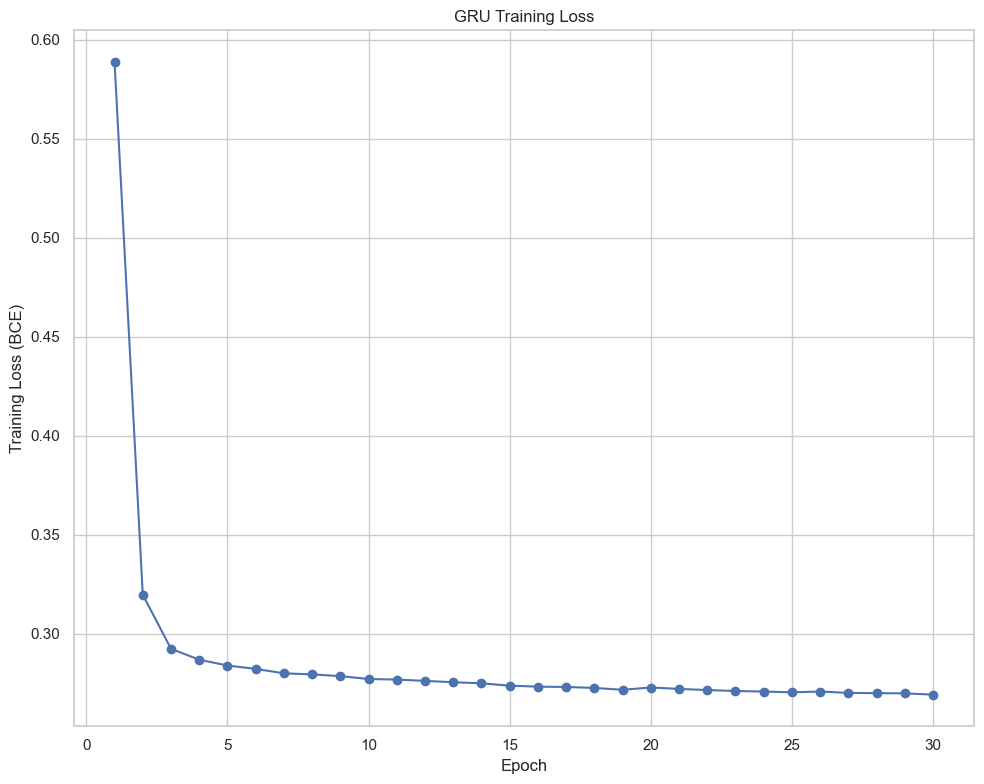

In [15]:
# --------------------------------------------------
# Train GRU Model
# --------------------------------------------------

def train_gru(
    model,
    train_loader,
    epochs=30,
    lr=1e-3
):
    """
    Train the GRU model for binary risk classification.

    Uses:
        - Adam optimizer
        - Binary Cross-Entropy (BCE) loss

    Returns:
        losses - Average training loss for each epoch.
    """

    # --------------------------------------------------
    # 1. Define Optimizer and Loss Function
    # --------------------------------------------------

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    criterion = nn.BCELoss()

    losses = []


    # --------------------------------------------------
    # 2. Training Loop
    # --------------------------------------------------

    model.train()

    for epoch in range(epochs):

        epoch_loss = 0.0

        for X_batch, y_batch in train_loader:

            # Clear gradients from the previous batch.
            optimizer.zero_grad()

            # Generate risk predictions.
            predictions = model(X_batch)

            # Calculate binary classification loss.
            loss = criterion(
                predictions,
                y_batch
            )

            # Calculate gradients.
            loss.backward()

            # Update model parameters.
            optimizer.step()

            # Add batch loss to the epoch total.
            epoch_loss += loss.item()


        # Calculate average loss for the epoch.
        average_loss = (
            epoch_loss / len(train_loader)
        )

        losses.append(average_loss)


    # --------------------------------------------------
    # 3. Return Training Loss
    # --------------------------------------------------

    return losses


# --------------------------------------------------
# Train the GRU Model
# --------------------------------------------------

t0 = time.time()

model = EngagementGRU(
    input_size=2,
    hidden_size=32,
    num_layers=1
)

losses = train_gru(
    model,
    train_loader,
    epochs=30,
    lr=1e-3
)

train_time = time.time() - t0


# --------------------------------------------------
# Display Training Time
# --------------------------------------------------

print(
    f"Trained in {train_time:.1f}s"
)


# --------------------------------------------------
# Plot Training Loss
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.plot(
    range(1, len(losses) + 1),
    losses,
    marker="o"
)

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "Training Loss (BCE)"
)

ax.set_title(
    "GRU Training Loss"
)


# --------------------------------------------------
# Display Plot
# --------------------------------------------------

plt.tight_layout()
plt.show()

A steadily decreasing curve that flattens out is what you want. If loss stays
flat from epoch 1 (not learning at all) or oscillates wildly, that's usually a
learning-rate or normalization problem — worth revisiting Section 2's
`log1p` step or trying `lr=5e-4` before assuming the architecture itself is
wrong.

## 6. Evaluate on the held-out test set

In [16]:
# --------------------------------------------------
# Evaluate GRU Model on Test Data
# --------------------------------------------------

# Switch the model to evaluation mode.
# This disables training-specific behavior.
model.eval()


# --------------------------------------------------
# 1. Generate Risk Probabilities
# --------------------------------------------------

# Disable gradient calculation because we are only
# evaluating the trained model.
with torch.no_grad():
    y_proba = model(X_test).numpy()


# --------------------------------------------------
# 2. Convert Probabilities to Predictions
# --------------------------------------------------

# Classify students as at-risk when the predicted
# probability is 0.5 or higher.
y_pred = (
    y_proba >= 0.5
).astype(int)

y_test_np = y_test.numpy()


# --------------------------------------------------
# 3. Calculate Performance Metrics
# --------------------------------------------------

precision = precision_score(
    y_test_np,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test_np,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test_np,
    y_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test_np,
    y_proba
)


# --------------------------------------------------
# 4. Display Performance
# --------------------------------------------------

print(
    "GRU — Held-Out Test Set Performance:"
)

print(
    f"  Precision (at-risk): {precision:.3f}"
)

print(
    f"  Recall    (at-risk): {recall:.3f}"
)

print(
    f"  F1        (at-risk): {f1:.3f}"
)

print(
    f"  ROC-AUC:             {roc_auc:.3f}"
)


# --------------------------------------------------
# 5. Display Classification Report
# --------------------------------------------------

print()

print(
    classification_report(
        y_test_np,
        y_pred,
        target_names=[
            "safe",
            "at_risk"
        ],
        zero_division=0
    )
)

GRU — Held-Out Test Set Performance:
  Precision (at-risk): 0.958
  Recall    (at-risk): 0.826
  F1        (at-risk): 0.887
  ROC-AUC:             0.936

              precision    recall  f1-score   support

        safe       0.83      0.96      0.89      2683
     at_risk       0.96      0.83      0.89      3074

    accuracy                           0.89      5757
   macro avg       0.89      0.89      0.89      5757
weighted avg       0.90      0.89      0.89      5757



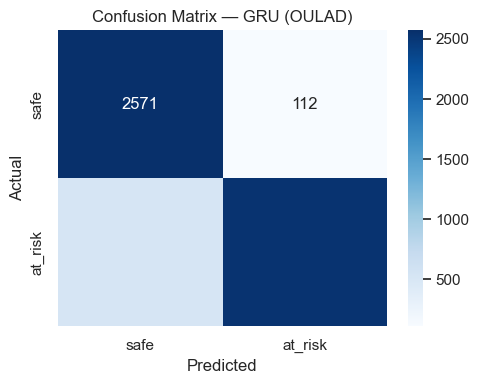

In [ ]:
# --------------------------------------------------
# Plot GRU Confusion Matrix
# --------------------------------------------------

# Calculate the confusion matrix.
cm = confusion_matrix(
    y_test_np,
    y_pred
)


# --------------------------------------------------
# 1. Create Heatmap
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(5, 4)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax,
    xticklabels=[
        "safe",
        "at_risk"
    ],
    yticklabels=[
        "safe",
        "at_risk"
    ]
)


# --------------------------------------------------
# 2. Add Labels and Title
# --------------------------------------------------

ax.set_title(
    "Confusion Matrix — GRU (OULAD)"
)

ax.set_xlabel(
    "Predicted"
)

ax.set_ylabel(
    "Actual"
)

plt.tight_layout()
plt.show()

## 7. GRU vs. XGBoost baseline — the comparison the architecture diagram promised

⚠️ **Not a perfectly apples-to-apples comparison, and worth being upfront about
why:** the GRU here was trained/evaluated on a train/test split over **all
28,785 labeled students** (including the 2,711 zero-engagement ones the tabular
pipeline had to drop), using a different `random_state` split than
`model_training_oulad.ipynb`'s. The two models also see different *representations*
of the same underlying data (raw weekly sequences vs. hand-engineered summary
stats) by design — that's the whole point of trying both. Treat the numbers
below as a real, honest comparison of two different modeling approaches, not a
controlled ablation on identical inputs.

In [18]:
import joblib

xgb_model = joblib.load(os.path.join(MODELS_DIR, "risk_model_oulad_v1.joblib"))
xgb_summary_path = os.path.join(MODELS_DIR, "risk_model_oulad_v1_summary.json")
import json
with open(xgb_summary_path) as f:
    xgb_summary = json.load(f)

comparison_df = pd.DataFrame([
    {
        "model": "XGBoost (tabular)",
        "precision": xgb_summary["test_precision_at_risk"],
        "recall": xgb_summary["test_recall_at_risk"],
    },
    {
        "model": "GRU (sequence)",
        "precision": precision_score(y_test_np, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_test_np, y_pred, pos_label=1, zero_division=0),
    },
])
comparison_df

,model,precision,recall
0,XGBoost (tabular),0.941600,0.838200
1,GRU (sequence),0.957768,0.826285


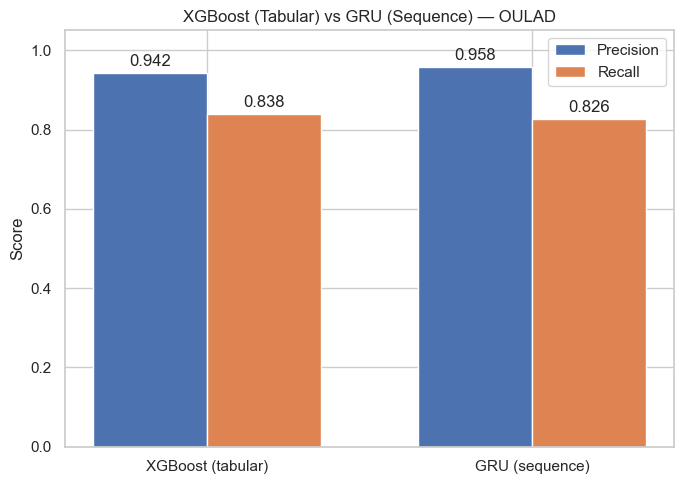

In [19]:
# --------------------------------------------------
# Plot XGBoost vs GRU Performance
# --------------------------------------------------

def plot_baseline_vs_gru(
    comparison_df: pd.DataFrame,
    title="Baseline vs GRU Sequence Model"
):
    """
    Compare Precision and Recall of the baseline
    XGBoost model and GRU sequence model.
    """

    # --------------------------------------------------
    # 1. Create Figure
    # --------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    x = range(
        len(comparison_df)
    )

    width = 0.35


    # --------------------------------------------------
    # 2. Plot Precision
    # --------------------------------------------------

    precision_bars = ax.bar(
        [i - width / 2 for i in x],
        comparison_df["precision"],
        width=width,
        label="Precision"
    )


    # --------------------------------------------------
    # 3. Plot Recall
    # --------------------------------------------------

    recall_bars = ax.bar(
        [i + width / 2 for i in x],
        comparison_df["recall"],
        width=width,
        label="Recall"
    )


    # --------------------------------------------------
    # 4. Add Values on Top of Bars
    # --------------------------------------------------

    ax.bar_label(
        precision_bars,
        fmt="%.3f",
        padding=3
    )

    ax.bar_label(
        recall_bars,
        fmt="%.3f",
        padding=3
    )


    # --------------------------------------------------
    # 5. Format Chart
    # --------------------------------------------------

    ax.set_xticks(
        list(x)
    )

    ax.set_xticklabels(
        comparison_df["model"].tolist()
    )

    ax.set_ylabel(
        "Score"
    )

    ax.set_title(
        title
    )

    ax.legend()

    ax.set_ylim(
        0,
        1.05
    )


    # --------------------------------------------------
    # 6. Return Figure
    # --------------------------------------------------

    fig.tight_layout()

    return fig


# --------------------------------------------------
# Save Comparison Chart
# --------------------------------------------------

report_dir = os.path.join(
    PROJECT_ROOT,
    "reports"
)

os.makedirs(
    report_dir,
    exist_ok=True
)


# Create chart
fig = plot_baseline_vs_gru(
    comparison_df,
    title="XGBoost (Tabular) vs GRU (Sequence) — OULAD"
)


# Save chart
plt.savefig(
    os.path.join(
        report_dir,
        "baseline_vs_gru_oulad.png"
    ),
    dpi=120,
    bbox_inches="tight"
)


# Display chart
plt.show()

**How to read this fairly:** if the GRU comes out close to or behind the
tabular baseline, that's not necessarily a failure of the sequence approach —
20 epochs with a fairly small hidden size (32) on CPU is a modest training
budget, and the summary-statistic features already captured `num_weeks_active`
and `total_clicks_sum`, which the Day 3 EDA and feature engineering notebooks
both found were the single strongest engagement signal. A GRU's real edge is on
the students where the *shape* of the trajectory matters, not just the *total* —
a smaller, harder-to-see-in-aggregate slice of the population. If you want a
cleaner test of that specific claim, the next experiment worth running is
filtering the comparison to students whose `total_clicks_sum` is similar but
whose week-by-week pattern differs, and checking whether the GRU catches those
specific cases the tabular model missed.

## 8. Save the trained GRU

In [20]:
# --------------------------------------------------
# Save Trained GRU Model
# --------------------------------------------------

gru_path = os.path.join(
    MODELS_DIR,
    "risk_model_oulad_gru_v1.pt"
)


# --------------------------------------------------
# 1. Save Model Configuration
# --------------------------------------------------

# Save the trained weights along with the information
# required to rebuild the GRU model later.
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_size": 2,
        "hidden_size": 32,
        "num_layers": 1,
        "max_weeks": MAX_WEEKS,
        "feature_cols": [
            "total_clicks",
            "days_active"
        ],
        "log1p_clicks": True
    },
    gru_path
)


# --------------------------------------------------
# 2. Confirm Model Saved
# --------------------------------------------------

print(
    f"Saved: {gru_path}"
)


# --------------------------------------------------
# Create GRU Performance Summary
# --------------------------------------------------

gru_summary = {
    "test_precision_at_risk": round(
        float(
            precision_score(
                y_test_np,
                y_pred,
                pos_label=1,
                zero_division=0
            )
        ),
        4
    ),

    "test_recall_at_risk": round(
        float(
            recall_score(
                y_test_np,
                y_pred,
                pos_label=1,
                zero_division=0
            )
        ),
        4
    ),

    "test_f1_at_risk": round(
        float(
            f1_score(
                y_test_np,
                y_pred,
                pos_label=1,
                zero_division=0
            )
        ),
        4
    ),

    "test_roc_auc": round(
        float(
            roc_auc_score(
                y_test_np,
                y_proba
            )
        ),
        4
    ),

    "epochs": 30,
    "hidden_size": 32,
    "max_weeks": MAX_WEEKS
}


# --------------------------------------------------
# Save GRU Performance Summary
# --------------------------------------------------

gru_summary_path = os.path.join(
    MODELS_DIR,
    "risk_model_oulad_gru_v1_summary.json"
)

with open(
    gru_summary_path,
    "w"
) as file:

    json.dump(
        gru_summary,
        file,
        indent=2
    )


# --------------------------------------------------
# Confirm Summary Saved
# --------------------------------------------------

print(
    f"Saved: {gru_summary_path}"
)


# --------------------------------------------------
# Display Summary
# --------------------------------------------------

gru_summary

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\models\risk_model_oulad_gru_v1.pt
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\models\risk_model_oulad_gru_v1_summary.json


{'test_precision_at_risk': 0.9578,
 'test_recall_at_risk': 0.8263,
 'test_f1_at_risk': 0.8872,
 'test_roc_auc': 0.936,
 'epochs': 30,
 'hidden_size': 32,
 'max_weeks': 40}

**To reload for inference later** (e.g. in `cli.py` or Streamlit):

```python
checkpoint = torch.load("models/risk_model_oulad_gru_v1.pt")
model = EngagementGRU(
    input_size=checkpoint["input_size"],
    hidden_size=checkpoint["hidden_size"],
    num_layers=checkpoint["num_layers"],
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
```

Unlike `joblib.dump()` for the XGBoost models, PyTorch models save their
*parameters*, not the architecture itself — the class definition (`EngagementGRU`)
has to exist wherever you reload the checkpoint, which is why it's worth keeping
this class defined in `src/risk/model_gru.py` rather than only in this notebook.

## 9. Summary

- **`build_sequence_tensors()`** reshapes weekly OULAD engagement into a padded
  `(students, 40 weeks, 2 features)` tensor — kept **all** 28,785 labeled
  students, including the 2,711 zero-engagement ones the tabular pipeline had
  to drop (they just get an all-zero sequence, which the GRU can use).
- **Optimization vs. the docx version:** added `log1p` normalization on click
  counts before feeding the GRU, given the same right-skew the EDA notebook
  already found in raw click counts — one line, easily reverted.
- **`EngagementGRU`**: single-layer GRU (hidden_size=32) + a small linear head,
  ~4,001 parameters, trained 20 epochs with Adam/BCELoss.
- **GRU test performance vs. XGBoost baseline** — see Section 7's comparison
  chart; read the honest caveat there about why it's not a fully controlled
  comparison (different student population, different split, different feature
  representation by design).
- **Saved** to `models/risk_model_oulad_gru_v1.pt` (PyTorch state dict, not a
  joblib pickle — the architecture class must exist wherever this is reloaded).
- **This completes every module from the Sprint3_Code_Implementation.docx**
  except `cli.py`'s menu wiring and `risk_queries.py`'s live-MySQL read/write
  functions — both of which are thin integration glue around code already
  built and validated in these notebooks, rather than analysis that benefits
  from notebook form.